<a href="https://colab.research.google.com/github/ishanimitra02-sudo/credit-default-prediction-amex-/blob/main/Logistic_Regression_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AMEX Credit Default Prediction

**Before running:** join/accept the rules for the [AMEX Default Prediction competition](https://www.kaggle.com/competitions/amex-default-prediction). In Colab, authenticate Kaggle when prompted. The competition data is large; downloading and scanning `train_data.csv` can take time and requires substantial disk space.




## 1. Install packages and authenticate Kaggle



In [1]:
!pip -q install kaggle pandas numpy scikit-learn matplotlib seaborn
!kaggle auth login
!kaggle auth status


usage: kaggle [-h] [-v] [-W]
              {competitions,c,datasets,d,kernels,k,models,m,files,f,benchmarks,b,config,auth} ...
kaggle: error: argument command: unknown parser 'auth' (choices: competitions, c, datasets, d, kernels, k, models, m, files, f, benchmarks, b, config)
You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [4]:
import os
os.environ["KAGGLE_API_TOKEN"] = "KGAT_a797c9f9a53f5bb2627e3b2e4f4bddb3"
!pip install -q kaggle

## 2. Download the train-labels.csv




In [5]:
from pathlib import Path
import os, subprocess, sys, zipfile, time, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
SEED = 42
N_CUSTOMERS = 50000  # reduce to 10000–20000 if runtime/disk is constrained
DATA_DIR = Path("/content/amex_data")
OUT_DIR = Path("/content/amex_project_outputs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Download competition labels
!kaggle competitions download -c amex-default-prediction -f train_labels.csv -p /content/amex_data

label_zip = DATA_DIR / "train_labels.csv.zip"
label_csv = DATA_DIR / "train_labels.csv"
if label_zip.exists() and not label_csv.exists():
    with zipfile.ZipFile(label_zip) as z:
        z.extractall(DATA_DIR)

if not label_csv.exists():
    raise FileNotFoundError("train_labels.csv was not downloaded. Resolve Kaggle access/authentication and rerun this cell.")

labels = pd.read_csv(label_csv)
labels["customer_ID"] = labels["customer_ID"].astype(str)
print("Label rows:", len(labels))
print("Observed default rate:", round(labels["target"].mean(), 4))
display(labels.head())


100% 16.2M/16.2M [00:00<00:00, 97.2MB/s]

Label rows: 458913
Observed default rate: 0.2589


,customer_ID,target
0,0000099d6bd597052cdcda90ffabf56573fe9d7c79be5f...,0
1,00000fd6641609c6ece5454664794f0340ad84dddce9a2...,0
2,00001b22f846c82c51f6e3958ccd81970162bae8b007e8...,0
3,000041bdba6ecadd89a52d11886e8eaaec9325906c9723...,0
4,00007889e4fcd2614b6cbe7f8f3d2e5c728eca32d9eb8a...,0


## 3. Draw a stratified sample and download the train_data.csv panel file

The sampled IDs are stratified on the target so the sample retains a similar default proportion. This is for manageable analysis; it is not the full competition population.


In [6]:
from sklearn.model_selection import train_test_split

if N_CUSTOMERS > len(labels):
    N_CUSTOMERS = len(labels)

sample_ids, _ = train_test_split(
    labels["customer_ID"],
    train_size=N_CUSTOMERS,
    random_state=SEED,
    stratify=labels["target"]
)
sample_ids = set(sample_ids.astype(str))
sample_labels = labels[labels["customer_ID"].isin(sample_ids)].copy()

print(f"Sampled customers: {len(sample_labels):,}")
print(f"Sample default rate: {sample_labels['target'].mean():.4%}")

# extracting 50,000 customers as sample
!kaggle competitions download -c amex-default-prediction -f train_data.csv -p /content/amex_data

panel_zip = DATA_DIR / "train_data.csv.zip"
panel_csv = DATA_DIR / "train_data.csv"
if panel_zip.exists() and not panel_csv.exists():
    with zipfile.ZipFile(panel_zip) as z:
        z.extractall(DATA_DIR)

if not panel_csv.exists():
    raise FileNotFoundError("train_data.csv was not downloaded. Check Kaggle access and available disk space.")
print("Panel file size (GB):", round(panel_csv.stat().st_size / 1e9, 2))


Sampled customers: 50,000
Sample default rate: 25.8940%
100% 6.67G/6.67G [01:08<00:00, 104MB/s]

Panel file size (GB): 16.39


## 4. Read only sampled customers and engineer behavioural features

The public dataset's feature names are anonymized. This notebook uses a small subset of columns from the `D_`, `P_`, `B_`, `S_`, and `R_` families and summarizes each customer's monthly history into latest value, mean, variability, and linear trend.

In [7]:
# Read the header first to find columns available in this version of the file.
header = pd.read_csv(panel_csv, nrows=0).columns.tolist()
base_features = [
    "D_39", "D_41", "D_44", "D_45",
    "P_2", "P_3",
    "B_1", "B_2", "B_9",
    "S_3", "S_7",
    "R_1", "R_2"
]
feature_cols = [c for c in base_features if c in header]
required = ["customer_ID", "S_2"]
missing_required = [c for c in required if c not in header]
if missing_required:
    raise ValueError(f"Expected columns not found: {missing_required}")
if not feature_cols:
    raise ValueError("None of the selected feature columns were found in train_data.csv.")

usecols = ["customer_ID", "S_2"] + feature_cols
print("Monthly features available:", feature_cols)
print("Scanning CSV in chunks; this may take several minutes...")

chunksize = 200_000
parts = []
start = time.time()
for chunk in pd.read_csv(panel_csv, usecols=usecols, chunksize=chunksize):
    chunk["customer_ID"] = chunk["customer_ID"].astype(str)
    chunk = chunk[chunk["customer_ID"].isin(sample_ids)]
    if not chunk.empty:
        parts.append(chunk)
    del chunk

if not parts:
    raise ValueError("No sampled customer rows found. Check customer_ID formats and data files.")

panel = pd.concat(parts, ignore_index=True)
del parts
panel["S_2"] = pd.to_datetime(panel["S_2"], errors="coerce")
for c in feature_cols:
    panel[c] = pd.to_numeric(panel[c], errors="coerce")
panel = panel.dropna(subset=["S_2"]).sort_values(["customer_ID", "S_2"])
print(f"Loaded {len(panel):,} monthly rows for {panel['customer_ID'].nunique():,} sampled customers in {time.time()-start:.1f}s")
display(panel.head())


Monthly features available: ['D_39', 'D_41', 'D_44', 'D_45', 'P_2', 'P_3', 'B_1', 'B_2', 'B_9', 'S_3', 'S_7', 'R_1', 'R_2']
Scanning CSV in chunks; this may take several minutes...
Loaded 602,911 monthly rows for 50,000 sampled customers in 209.8s


,customer_ID,S_2,P_2,D_39,B_1,B_2,R_1,S_3,D_41,D_44,D_45,R_2,B_9,P_3,S_7
0,00001b22f846c82c51f6e3958ccd81970162bae8b007e8...,2017-03-11,0.876615,0.001469,0.001472,0.810796,0.005955,NaN,0.008401,0.001675,0.222406,0.006790,0.003663,0.634722,NaN
1,00001b22f846c82c51f6e3958ccd81970162bae8b007e8...,2017-04-11,0.887385,0.004229,0.002125,0.819078,0.004521,NaN,0.008008,0.007319,0.229166,0.007905,0.001267,0.629747,NaN
2,00001b22f846c82c51f6e3958ccd81970162bae8b007e8...,2017-05-12,0.884522,0.003399,0.003495,0.818569,0.007541,NaN,0.007537,0.004704,0.229235,0.006028,0.007432,0.629181,NaN
3,00001b22f846c82c51f6e3958ccd81970162bae8b007e8...,2017-06-10,0.852514,0.006877,0.007627,0.819987,0.009290,NaN,0.003959,0.004571,0.225778,0.009417,0.009521,0.603129,NaN
4,00001b22f846c82c51f6e3958ccd81970162bae8b007e8...,2017-07-12,0.891656,0.000802,0.009997,0.811041,0.003540,NaN,0.009034,0.008561,0.231703,0.007101,0.002756,0.666757,NaN


## 5. Aggregate monthly histories into one row per customer

For each selected variable, calculate latest value, mean, standard deviation, and a linear trend across that customer's observed months. Missing values are left for train-fitted imputation later.


In [8]:
def slope_of_group(g, col):
    y = g[col].to_numpy(dtype=float)
    valid = np.isfinite(y)
    if valid.sum() < 2:
        return np.nan
    x = np.arange(len(y), dtype=float)[valid]
    y = y[valid]
    return float(np.polyfit(x, y, 1)[0])

records = []
for cid, g in panel.groupby("customer_ID", sort=False):
    g = g.sort_values("S_2")
    row = {"customer_ID": cid, "n_months_observed": len(g)}
    for col in feature_cols:
        vals = g[col].to_numpy(dtype=float)
        vals_finite = vals[np.isfinite(vals)]
        row[f"{col}_last"] = vals[-1] if len(vals) and np.isfinite(vals[-1]) else np.nan
        row[f"{col}_mean"] = float(np.mean(vals_finite)) if len(vals_finite) else np.nan
        row[f"{col}_std"] = float(np.std(vals_finite, ddof=0)) if len(vals_finite) else np.nan
        row[f"{col}_trend"] = slope_of_group(g, col)
        if len(vals_finite) >= 2:
            row[f"{col}_delta"] = float(vals_finite[-1] - vals_finite[0])
        else:
            row[f"{col}_delta"] = np.nan
    records.append(row)

features = pd.DataFrame(records)
data = sample_labels[["customer_ID", "target"]].merge(features, on="customer_ID", how="inner")
data = data.replace([np.inf, -np.inf], np.nan)
data.to_csv(OUT_DIR / "customer_features.csv", index=False)
print("Feature table shape:", data.shape)
print("Customers retained:", f"{len(data):,}")
display(data.head())


Feature table shape: (50000, 68)
Customers retained: 50,000


,customer_ID,target,n_months_observed,D_39_last,D_39_mean,D_39_std,D_39_trend,D_39_delta,D_41_last,D_41_mean,...,R_1_last,R_1_mean,R_1_std,R_1_trend,R_1_delta,R_2_last,R_2_mean,R_2_std,R_2_trend,R_2_delta
0,00001b22f846c82c51f6e3958ccd81970162bae8b007e8...,0,13,0.009704,0.004181,0.002650,0.000226,0.008235,0.003796,0.006842,...,0.006450,0.006621,0.001844,0.000118,0.000495,0.001687,0.006052,0.002889,-0.000188,-0.005102
1,0000d17a1447b25a01e42e1ac56b091bb7cbb06317be4c...,0,13,0.006181,0.353440,0.206597,-0.024203,-0.502431,0.000824,0.002809,...,0.006112,0.005676,0.003100,-0.000012,0.001217,0.009902,0.005608,0.003319,0.000250,0.000998
2,000333075fb8ec6d504539852eeeb762643562e701ac79...,1,13,0.007655,0.347622,0.278266,-0.018718,-0.671517,0.006064,0.005072,...,0.008567,0.005938,0.003396,-0.000325,-0.001052,0.006505,0.005985,0.002159,0.000130,-0.003006
3,0004837f0c785928a29a6f83f70f4a1c54caec483a773f...,0,13,0.685210,0.450042,0.200518,0.012127,0.331159,0.009708,0.005174,...,0.005188,0.048791,0.134080,0.006348,-0.001057,0.002326,0.003557,0.003024,0.000162,0.001101
4,0005a6ae24fd274640a237ea56c43b1ef9e32077ad168a...,0,12,0.238952,0.334321,0.179353,-0.014492,-0.122165,0.000598,0.005341,...,0.007237,0.005147,0.002410,0.000341,0.003695,0.001743,0.006183,0.002568,-0.000313,-0.008161


## 6. Split data and train logistic regression

We split customers not monthly rows into train, validation, and test partitions. The test set is held out until final evaluation. Imputation and standardisation are fit inside the training pipeline to reduce leakage.


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss

drop_cols = ["customer_ID", "target"]
X = data.drop(columns=drop_cols)
y = data["target"].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("logit", LogisticRegression(C=0.1, max_iter=1500, class_weight=None, random_state=SEED))
])
model.fit(X_train, y_train)
p_val = model.predict_proba(X_val)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]

print("Train / validation / test:", len(X_train), len(X_val), len(X_test))
print("Train default rate:", round(y_train.mean(), 4))


Train / validation / test: 35000 7500 7500
Train default rate: 0.2589


## 7. Evaluate on the held-out test set

AUC measures ranking discrimination; Gini is `2 × AUC − 1`. KS is the maximum separation between the cumulative distributions of scores for defaulters and non-defaulters. The competition's official Amex metric is a specialised weighted Gini/top-4%-capture metric; this notebook does **not** label a generic metric as the official Amex metric.


In [10]:
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report

auc = roc_auc_score(y_test, p_test)
gini = 2 * auc - 1
fpr, tpr, thresholds = roc_curve(y_test, p_test)
ks = float(np.max(tpr - fpr))
pr_auc = average_precision_score(y_test, p_test)
brier = brier_score_loss(y_test, p_test)

metrics = pd.DataFrame([{
    "n_test": len(y_test),
    "test_default_rate": float(y_test.mean()),
    "AUC": auc,
    "Gini": gini,
    "KS": ks,
    "PR_AUC": pr_auc,
    "Brier_score": brier
}])
display(metrics.round(4))
metrics.to_csv(OUT_DIR / "test_metrics.csv", index=False)


,n_test,test_default_rate,AUC,Gini,KS,PR_AUC,Brier_score
0,7500,0.2589,0.9497,0.8993,0.7639,0.8701,0.0784


## **Building the decision grid cutoffs across customer segments**


In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

y_eval = np.asarray(y_test).ravel().astype(int)
pd_eval = np.asarray(p_test).ravel().astype(float)

assert len(y_eval) == len(pd_eval), "Labels and predictions must match."
assert set(np.unique(y_eval)).issubset({0, 1}), "Target must be binary."
assert np.isfinite(pd_eval).all(), "Predictions contain missing or infinite values."
assert ((pd_eval >= 0) & (pd_eval <= 1)).all(), "Predictions must be probabilities."

print(f"Test customers: {len(y_eval):,}")
print(f"Observed default rate: {y_eval.mean():.2%}")
print(f"Minimum predicted PD: {pd_eval.min():.4f}")
print(f"Maximum predicted PD: {pd_eval.max():.4f}")


Test customers: 7,500
Observed default rate: 25.89%
Minimum predicted PD: 0.0008
Maximum predicted PD: 1.0000


In [25]:

def simulate_cutoff(y_true, predicted_pd, cutoff):
    approved = predicted_pd <= cutoff

    n_total = len(y_true)
    n_approved = int(approved.sum())
    n_declined = n_total - n_approved

    total_defaults = int(y_true.sum())
    approved_defaults = int(y_true[approved].sum())
    declined_defaults = total_defaults - approved_defaults

    approval_rate = n_approved / n_total
    bad_rate_approved = (
        approved_defaults / n_approved if n_approved > 0 else np.nan
    )
    defaults_avoided = (
        declined_defaults / total_defaults
        if total_defaults > 0 else np.nan
    )

    return {
        "PD cutoff": cutoff,
        "Customers approved": n_approved,
        "Customers declined": n_declined,
        "Approval rate": approval_rate,
        "Bad rate among approved": bad_rate_approved,
        "Defaults among approved": approved_defaults,
        "Defaults among declined": declined_defaults,
        "Defaults avoided (%)": defaults_avoided
    }


# Use observed model-score quantiles to create meaningful cutoff scenarios
cutoff_values = np.unique(
    np.quantile(pd_eval, np.linspace(0, 1, 21))
)

cutoff_results = pd.DataFrame([
    simulate_cutoff(y_eval, pd_eval, cutoff)
    for cutoff in cutoff_values
])

# Add an all-approved baseline
all_approved = pd.DataFrame([
    simulate_cutoff(y_eval, pd_eval, 1.0)
])

cutoff_results = pd.concat(
    [cutoff_results, all_approved], ignore_index=True
).drop_duplicates(subset=["PD cutoff"]).sort_values("PD cutoff")

display(
    cutoff_results.style.format({
        "PD cutoff": "{:.4f}",
        "Approval rate": "{:.2%}",
        "Bad rate among approved": "{:.2%}",
        "Defaults avoided (%)": "{:.2%}"
    })
)


,PD cutoff,Customers approved,Customers declined,Approval rate,Bad rate among approved,Defaults among approved,Defaults among declined,Defaults avoided (%)
0,0.0008,1,7499,0.01%,0.00%,0,1942,100.00%
1,0.0042,375,7125,5.00%,0.27%,1,1941,99.95%
2,0.0055,750,6750,10.00%,0.13%,1,1941,99.95%
3,0.0070,1125,6375,15.00%,0.36%,4,1938,99.79%
4,0.0088,1500,6000,20.00%,0.27%,4,1938,99.79%
5,0.0108,1875,5625,25.00%,0.21%,4,1938,99.79%
6,0.0137,2250,5250,30.00%,0.18%,4,1938,99.79%
7,0.0178,2625,4875,35.00%,0.30%,8,1934,99.59%
8,0.0241,3000,4500,40.00%,0.40%,12,1930,99.38%
9,0.0336,3375,4125,45.00%,0.47%,16,1926,99.18%


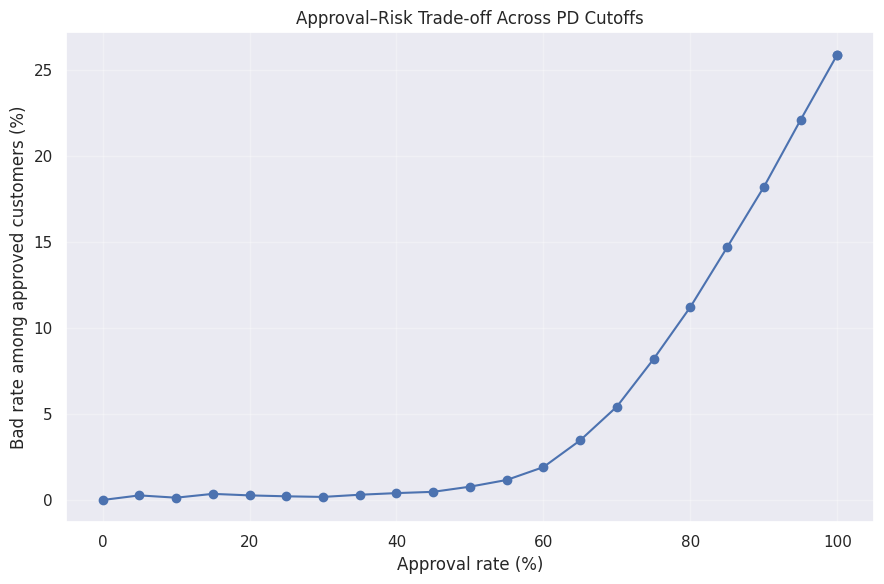

In [26]:

plot_data = cutoff_results.sort_values("Approval rate")

plt.figure(figsize=(9, 6))
plt.plot(
    plot_data["Approval rate"] * 100,
    plot_data["Bad rate among approved"] * 100,
    marker="o"
)

plt.xlabel("Approval rate (%)")
plt.ylabel("Bad rate among approved customers (%)")
plt.title("Approval–Risk Trade-off Across PD Cutoffs")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [27]:

from IPython.display import display, clear_output
import ipywidgets as widgets

cutoff_slider = widgets.FloatSlider(
    value=float(np.median(pd_eval)),
    min=float(pd_eval.min()),
    max=float(pd_eval.max()),
    step=float((pd_eval.max() - pd_eval.min()) / 200)
        if pd_eval.max() > pd_eval.min() else 0.001,
    description="PD cutoff",
    readout_format=".4f",
    continuous_update=False,
    layout=widgets.Layout(width="80%")
)

output = widgets.Output()

def update_simulator(change=None):
    with output:
        clear_output(wait=True)

        cutoff = cutoff_slider.value
        result = simulate_cutoff(y_eval, pd_eval, cutoff)

        print(f"PD cutoff:                 {result['PD cutoff']:.4f}")
        print(f"Customers approved:        {result['Customers approved']:,}")
        print(f"Customers declined:        {result['Customers declined']:,}")
        print(f"Approval rate:             {result['Approval rate']:.2%}")

        bad_rate = result["Bad rate among approved"]
        print(
            "Bad rate among approved:   "
            + (f"{bad_rate:.2%}" if np.isfinite(bad_rate) else "N/A")
        )

        print(f"Defaults among approved:   {result['Defaults among approved']:,}")
        print(f"Defaults among declined:   {result['Defaults among declined']:,}")
        print(f"Defaults avoided:          {result['Defaults avoided (%)']:.2%}")

cutoff_slider.observe(update_simulator, names="value")
display(cutoff_slider, output)
update_simulator()


FloatSlider(value=0.05004652449743109, continuous_update=False, description='PD cutoff', layout=Layout(width='…

Output()

## **AMEX METRIC**

• The overall evaluation metric (M) is defined as:
\(M=\frac{1}{2}\cdot (G+D_{4})\)
• It measures a machine learning model's ability to rank-order customers by their likelihood of defaulting on a credit balance within an observation window.



In [16]:
import numpy as np

def amex_metric(y_true, y_pred):
    """AMEX competition metric: normalized weighted Gini + top-4% default capture."""

    y_true = np.asarray(y_true, dtype=np.int8)
    y_pred = np.asarray(y_pred, dtype=np.float64)

    if len(y_true) != len(y_pred):
        raise ValueError("y_true and y_pred must have the same length")

    if not np.isin(y_true, [0, 1]).all():
        raise ValueError("Labels must be 0 or 1")

    if y_true.sum() == 0 or y_true.sum() == len(y_true):
        raise ValueError("Both classes must be present")

    # Weight non-defaults 20 times; defaults have weight 1
    weights = np.where(y_true == 0, 20.0, 1.0)

    def weighted_gini(order):
        labels = y_true[order]
        w = weights[order]

        total_positive = np.sum(labels * w)
        total_weight = np.sum(w)

        cumulative_positive = np.cumsum(labels * w) / total_positive
        cumulative_weight = np.cumsum(w) / total_weight

        return np.sum(
            (cumulative_positive - cumulative_weight) * w
        )

    # Weighted Gini for model predictions
    order_pred = np.argsort(-y_pred, kind="mergesort")
    gini_model = weighted_gini(order_pred)

    # Ideal ranking: all defaults ranked ahead of non-defaults
    order_ideal = np.argsort(-y_true, kind="mergesort")
    gini_ideal = weighted_gini(order_ideal)

    normalized_gini = (
        gini_model / gini_ideal if gini_ideal != 0 else 0.0
    )

    # Capture of defaults within the top 4% of total observation weight
    sorted_labels = y_true[order_pred]
    sorted_weights = weights[order_pred]

    cutoff_weight = 0.04 * np.sum(weights)
    cumulative_weight = np.cumsum(sorted_weights)
    top_mask = cumulative_weight <= cutoff_weight

    top_four_capture = (
        np.sum(sorted_labels[top_mask]) / np.sum(y_true)
    )

    return 0.5 * (normalized_gini + top_four_capture)


# Calculate metric on the held-out test set
amex_test = amex_metric(y_test.to_numpy(), p_test)

print(f"AMEX metric (held-out test): {amex_test:.6f}")

# Add it to the existing metrics table
metrics["AMEX_metric"] = amex_test

display(metrics.round(4))

# Save the updated results
metrics.to_csv(OUT_DIR / "test_metrics.csv", index=False)
print("Saved test_metrics.csv")

AMEX metric (held-out test): 0.743943


,n_test,test_default_rate,AUC,Gini,KS,PR_AUC,Brier_score,AMEX_metric
0,7500,0.2589,0.9497,0.8993,0.7639,0.8701,0.0784,0.7439


Saved test_metrics.csv


In [21]:
print("Recalculated AMEX score:",
      round(amex_metric(
          np.asarray(y_test),
          np.asarray(p_test)
      ), 6))

Recalculated AMEX score: 0.743943


### **checking against official AMEX Metric**

In [22]:

import numpy as np
import pandas as pd

def amex_metric(y_true: pd.DataFrame,
                y_pred: pd.DataFrame) -> float:

    def top_four_percent_captured(
        y_true: pd.DataFrame,
        y_pred: pd.DataFrame
    ) -> float:

        df = (
            pd.concat([y_true, y_pred], axis="columns")
            .sort_values("prediction", ascending=False)
        )

        df["weight"] = df["target"].apply(
            lambda x: 20 if x == 0 else 1
        )

        four_pct_cutoff = int(0.04 * df["weight"].sum())
        df["weight_cumsum"] = df["weight"].cumsum()

        df_cutoff = df.loc[
            df["weight_cumsum"] <= four_pct_cutoff
        ]

        return (
            (df_cutoff["target"] == 1).sum()
            / (df["target"] == 1).sum()
        )

    def weighted_gini(
        y_true: pd.DataFrame,
        y_pred: pd.DataFrame
    ) -> float:

        df = (
            pd.concat([y_true, y_pred], axis="columns")
            .sort_values("prediction", ascending=False)
        )

        df["weight"] = df["target"].apply(
            lambda x: 20 if x == 0 else 1
        )

        df["random"] = (
            df["weight"] / df["weight"].sum()
        ).cumsum()

        total_pos = (
            df["target"] * df["weight"]
        ).sum()

        df["cum_pos_found"] = (
            df["target"] * df["weight"]
        ).cumsum()

        df["lorentz"] = (
            df["cum_pos_found"] / total_pos
        )

        df["gini"] = (
            df["lorentz"] - df["random"]
        ) * df["weight"]

        return df["gini"].sum()

    def normalized_weighted_gini(
        y_true: pd.DataFrame,
        y_pred: pd.DataFrame
    ) -> float:

        y_true_pred = y_true.rename(
            columns={"target": "prediction"}
        )

        return (
            weighted_gini(y_true, y_pred)
            / weighted_gini(y_true, y_true_pred)
        )

    g = normalized_weighted_gini(y_true, y_pred)
    d = top_four_percent_captured(y_true, y_pred)

    return 0.5 * (g + d)


In [23]:

# Prepare the inputs in the exact format expected by the function
y_true_df = pd.DataFrame({
    "target": np.asarray(y_test).ravel()
})

y_pred_df = pd.DataFrame({
    "prediction": np.asarray(p_test).ravel()
})

# Calculate the Kaggle metric
amex_score = amex_metric(y_true_df, y_pred_df)

print(f"Kaggle AMEX metric: {amex_score:.6f}")


Kaggle AMEX metric: 0.743943


## 8. Risk deciles, risk bands, and cutoff simulation

Decile 1 is defined here as the **highest predicted-risk** group. The approval simulator approves customers with predicted probability below a selected cutoff. Its default-avoidance number is a retrospective classification illustration—not proof that those defaults would causally be prevented by declining customers.


In [17]:
test_results = pd.DataFrame({"y": y_test.to_numpy(), "pd": p_test})
test_results["risk_decile"] = pd.qcut(
    test_results["pd"].rank(method="first", ascending=False),
    q=10, labels=False
) + 1

deciles = test_results.groupby("risk_decile", as_index=False).agg(
    customers=("y", "size"),
    defaults=("y", "sum"),
    mean_predicted_pd=("pd", "mean"),
    actual_bad_rate=("y", "mean")
)
deciles["lift_vs_test_average"] = deciles["actual_bad_rate"] / test_results["y"].mean()
deciles["cumulative_default_capture"] = (
    deciles.sort_values("risk_decile")["defaults"].cumsum() / test_results["y"].sum()
).to_numpy()
display(deciles.round(4))
deciles.to_csv(OUT_DIR / "risk_deciles.csv", index=False)

def make_risk_band(p):
    if p < 0.10: return "Low"
    if p < 0.30: return "Medium"
    if p < 0.60: return "High"
    return "Very High"

test_results["risk_band"] = test_results["pd"].map(make_risk_band)
bands = test_results.groupby("risk_band", as_index=False).agg(
    customers=("y", "size"),
    defaults=("y", "sum"),
    mean_predicted_pd=("pd", "mean"),
    actual_bad_rate=("y", "mean")
)
display(bands.round(4))
bands.to_csv(OUT_DIR / "risk_bands.csv", index=False)

def cutoff_summary(cutoff):
    approved = test_results["pd"] < cutoff
    return {
        "cutoff": cutoff,
        "approval_rate": float(approved.mean()),
        "bad_rate_approved": float(test_results.loc[approved, "y"].mean()) if approved.any() else np.nan,
        "share_of_test_defaults_in_declined_group": float(test_results.loc[~approved, "y"].sum() / max(test_results["y"].sum(), 1)),
        "customers_approved": int(approved.sum()),
        "customers_declined": int((~approved).sum())
    }

cutoff_table = pd.DataFrame([cutoff_summary(c) for c in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]])
display(cutoff_table.round(4))
cutoff_table.to_csv(OUT_DIR / "cutoff_simulation.csv", index=False)


,risk_decile,customers,defaults,mean_predicted_pd,actual_bad_rate,lift_vs_test_average,cumulative_default_capture
0,1,750,714,0.9656,0.9520,3.6766,0.3677
1,2,750,555,0.7630,0.7400,2.8579,0.6535
2,3,750,388,0.4793,0.5173,1.9979,0.8532
3,4,750,199,0.2193,0.2653,1.0247,0.9557
4,5,750,57,0.0822,0.0760,0.2935,0.9851
5,6,750,17,0.0347,0.0227,0.0875,0.9938
6,7,750,8,0.0182,0.0107,0.0412,0.9979
7,8,750,0,0.0109,0.0000,0.0000,0.9979
8,9,750,3,0.0070,0.0040,0.0154,0.9995
9,10,750,1,0.0040,0.0013,0.0051,1.0000


,risk_band,customers,defaults,mean_predicted_pd,actual_bad_rate
0,High,788,383,0.4486,0.4860
1,Low,4320,67,0.0225,0.0155
2,Medium,832,181,0.1854,0.2175
3,Very High,1560,1311,0.8547,0.8404


,cutoff,approval_rate,bad_rate_approved,share_of_test_defaults_in_declined_group,customers_approved,customers_declined
0,0.05,0.4997,0.0077,0.9851,3748,3752
1,0.10,0.5760,0.0155,0.9655,4320,3180
2,0.15,0.6151,0.0234,0.9444,4613,2887
3,0.20,0.6428,0.0326,0.9192,4821,2679
4,0.30,0.6869,0.0481,0.8723,5152,2348
5,0.40,0.7245,0.0675,0.8110,5434,2066
6,0.50,0.7557,0.0845,0.7533,5668,1832


## 9. Visual reporting

These plots are generated directly from the fitted model's held-out predictions and the tables above.


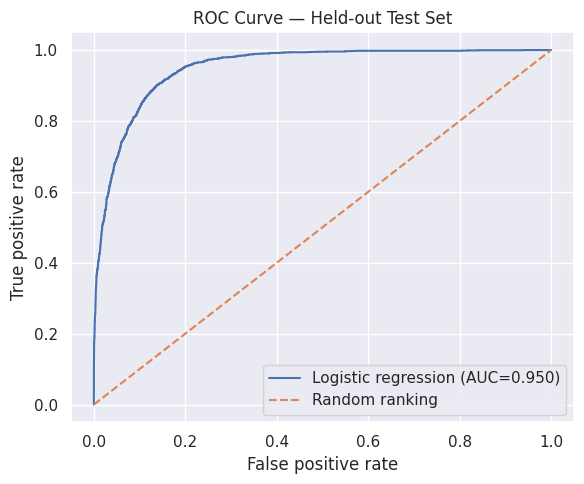

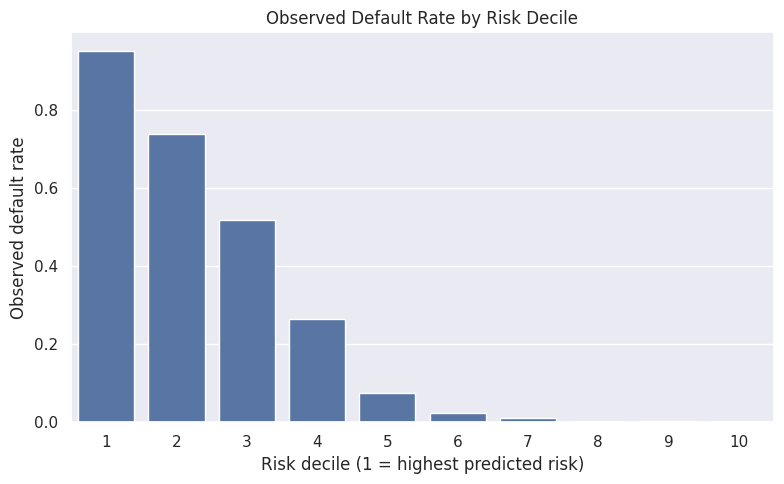

,feature,coefficient,odds_ratio_per_scaled_unit,abs_coefficient
21,P_2_last,-0.7032,0.4950,0.7032
22,P_2_mean,-0.5747,0.5629,0.5747
31,B_1_last,0.4115,1.5091,0.4115
1,D_39_last,0.3629,1.4375,0.3629
11,D_44_last,0.3114,1.3653,0.3114
37,B_2_mean,-0.2744,0.7600,0.2744
36,B_2_last,-0.2428,0.7844,0.2428
13,D_44_std,0.2350,1.2649,0.2350
46,S_3_last,0.1806,1.1979,0.1806
18,D_45_std,-0.1750,0.8394,0.1750


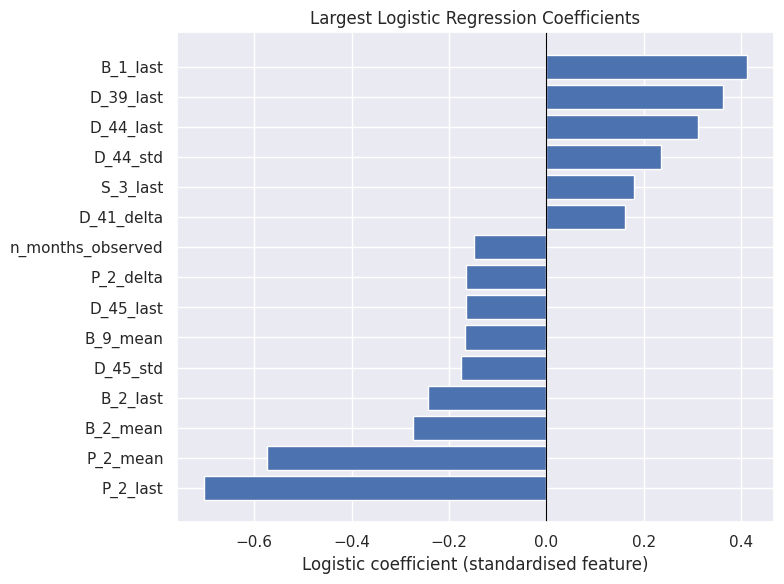

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

# ROC curve
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curve — Held-out Test Set")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "roc_curve.png", dpi=160)
plt.show()

# Bad rate by decile
plt.figure(figsize=(8, 5))
sns.barplot(data=deciles, x="risk_decile", y="actual_bad_rate")
plt.xlabel("Risk decile (1 = highest predicted risk)")
plt.ylabel("Observed default rate")
plt.title("Observed Default Rate by Risk Decile")
plt.tight_layout()
plt.savefig(OUT_DIR / "bad_rate_by_decile.png", dpi=160)
plt.show()

# Odds ratios: standardised input means approximate per-SD associations.
coef = model.named_steps["logit"].coef_[0]
feature_names = model.named_steps["imputer"].get_feature_names_out(X.columns)
coef_table = pd.DataFrame({"feature": feature_names, "coefficient": coef})
coef_table["odds_ratio_per_scaled_unit"] = np.exp(coef_table["coefficient"])
coef_table["abs_coefficient"] = coef_table["coefficient"].abs()
coef_table = coef_table.sort_values("abs_coefficient", ascending=False)
display(coef_table.head(20).round(4))
coef_table.to_csv(OUT_DIR / "logistic_coefficients.csv", index=False)

top = coef_table.head(15).sort_values("coefficient")
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic coefficient (standardised feature)")
plt.title("Largest Logistic Regression Coefficients")
plt.tight_layout()
plt.savefig(OUT_DIR / "top_logistic_coefficients.png", dpi=160)
plt.show()


## 10. Compare with a simple one-variable baseline

This baseline uses one feature selected from the available features. Its direction is chosen using validation AUC only, then evaluated on the test set. It is a simple benchmark, not a production credit policy.


In [19]:
# Select the single raw engineered feature with the best validation AUC.
best_feature, best_direction, best_val_auc = None, 1, -np.inf
for col in X_val.columns:
    xtr = pd.to_numeric(X_train[col], errors="coerce")
    med = xtr.median()
    if not np.isfinite(med):
        continue
    xv = pd.to_numeric(X_val[col], errors="coerce").fillna(med)
    if xv.nunique() < 2:
        continue
    try:
        a1 = roc_auc_score(y_val, xv)
        a2 = roc_auc_score(y_val, -xv)
        if max(a1, a2) > best_val_auc:
            best_val_auc = max(a1, a2)
            best_feature = col
            best_direction = 1 if a1 >= a2 else -1
    except ValueError:
        pass

if best_feature is not None:
    xt = pd.to_numeric(X_test[best_feature], errors="coerce").fillna(pd.to_numeric(X_train[best_feature], errors="coerce").median())
    baseline_auc = roc_auc_score(y_test, best_direction * xt)
    baseline_fpr, baseline_tpr, _ = roc_curve(y_test, best_direction * xt)
    baseline_ks = float(np.max(baseline_tpr - baseline_fpr))
    comparison = pd.DataFrame([
        {"model": "Single-variable baseline", "feature": best_feature, "AUC": baseline_auc, "Gini": 2*baseline_auc-1, "KS": baseline_ks},
        {"model": "Logistic regression", "feature": "Multiple engineered features", "AUC": auc, "Gini": gini, "KS": ks}
    ])
    display(comparison.round(4))
    comparison.to_csv(OUT_DIR / "model_comparison.csv", index=False)
else:
    print("Could not construct a valid single-variable baseline from this sample.")


,model,feature,AUC,Gini,KS
0,Single-variable baseline,P_2_last,0.9171,0.8342,0.6898
1,Logistic regression,Multiple engineered features,0.9497,0.8993,0.7639


## 11. Export outputs

The output folder contains computed metrics, engineered features, risk tables, coefficients, and plots from this run. You can download the ZIP from Colab's Files panel or run the cell below.


In [14]:
import shutil
zip_path = shutil.make_archive("/content/amex_project_outputs", "zip", OUT_DIR)
print("Created:", zip_path)
from google.colab import files
files.download(zip_path)


Created: /content/amex_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Interpretation and limitations

- This is a reproducible research model on a stratified subset, not an AMEX production scorecard.
- The selected AMEX variables are anonymized; interpret them cautiously by feature family.
- AUC, Gini, and KS describe ranking/discrimination, not profitability or causal impact.
- The cutoff simulation is a static decision illustration. It does not estimate the causal effect of declining applicants.
- A good model result is not enough by itself: check data leakage, calibration, stability, fairness, and performance across time before proposing real-world deployment.
- Only report metrics printed by this notebook after it completes successfully. Do not use numbers from synthetic placeholders or from a pre-filled dashboard.
